# Upgraded finetuning data to include skewed and rotated images

Car Fleet (1,400 images total):
1,260 clean, upright car images (90%)
140 skewed car images (10%)


Motorbike Fleet (1,400 images total):
1,260 clean motorbike images (90%)
140 skewed motorbike images (10%)


Negative Background Fleet (200 images total):
200 empty background images containing zero license plates (campus gates, empty tarmac, vehicle grills, textured walls).

# Checking if T4 GPU is used (before ssh)

In [1]:
!nvidia-smi

Mon Oct 26 06:36:45 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   39C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch
print(torch.cuda.is_available())
print(torch.cuda.get_device_name(0))

True
Tesla T4


# Installing dependencies

In [3]:
# Install standard, stable versions compatible with the GPU 
%pip install -q ultralytics roboflow torch albumentations

In [4]:
from ultralytics import YOLO
from roboflow import Roboflow
from google.colab import files
import cv2
import random
import shutil
import yaml
import glob

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.


In [5]:
import os

# Download Vietnamese License Plate Dataset from Roboflow

In [ ]:
rf = Roboflow(api_key="") # Replace with your actual Roboflow API key
# https://app.roboflow.com/alphajack2006-gmail-com/vietnamese-car-license-plate-vlbzz/trainz
# location of the dataset in Roboflow.
car_dominant_project = rf.workspace("alphajack2006-gmail-com").project("vietnamese-car-license-plate-vlbzz")
car_dominant_version = car_dominant_project.version(1)
car_dominant_dataset = car_dominant_version.download("yolov8") # this one alr works
moto_dominant_project = rf.workspace("alphajack2006-gmail-com").project("motorcycle-license-plate-sksvk")
moto_dominant_version = moto_dominant_project.version(1)
moto_dominant_dataset = moto_dominant_version.download("yolov8")
neg_sam_project = rf.workspace("alphajack2006-gmail-com").project("road-and-pavement-hc3qg-qsmcl")
neg_sam_version = neg_sam_project.version(1)
neg_sam_dataset = neg_sam_version.download("yolov8")
                

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Vietnamese-Car-License-Plate--1 in yolov8:: 100%|██████████| 16513/16513 [00:01<00:00, 9084.99it/s] 

loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to Motorcycle-license-plate-1 in yolov8:: 100%|██████████| 3500/3500 [00:00<00:00, 12453.49it/s]

loading Roboflow workspace...


loading Roboflow project...



Extracting Dataset Version Zip to road-and-pavement-1 in yolov8:: 100%|██████████| 5584/5584 [00:04<00:00, 1211.33it/s]


In [7]:
car_dir = car_dominant_dataset.location
moto_dir = moto_dominant_dataset.location
unified_dir = "/content/dataset_unified"

print(f"Car dataset downloaded to: {car_dir}")
print(f"Moto dataset downloaded to: {moto_dir}")
print(f"Unified dataset will be stored in: {unified_dir}")

Car dataset downloaded to: /content/Vietnamese-Car-License-Plate--1
Moto dataset downloaded to: /content/Motorcycle-license-plate-1
Unified dataset will be stored in: /content/dataset_unified


## merging the dataset

In [8]:
splits = ["train", "valid"]
for split in splits:
    os.makedirs(os.path.join(unified_dir, split, "images"), exist_ok=True)
    os.makedirs(os.path.join(unified_dir, split, "labels"), exist_ok=True)

def merge_datasets(src_dir, prefix, max_train_samples=None, seed=40):
    # brekak down the source directories for images and labels
    for split in splits:
        img_src = os.path.join(src_dir, split, "images")
        lbl_src = os.path.join(src_dir, split, "labels")

        if not os.path.exists(img_src):
            alt_split = "valid" if split == "valid" else "valid"
            img_src = os.path.join(src_dir, alt_split, "images")
            lbl_src = os.path.join(src_dir, alt_split, "labels")

        valid_exts = (".jpg", ".jpeg", ".png")
        all_images = [f for f in os.listdir(img_src) if f.lower().endswith(valid_exts)] # any image that has a valid extension

        if split == "train" and max_train_samples and len(all_images) >max_train_samples:
            random.seed(seed)
            selected_images = random.sample(all_images, max_train_samples)
            print(f"[{prefix.upper()} - {split} ; downsampled from {len(all_images)} to {len(selected_images)} images]")
        else:
            selected_images = all_images
            print(f"[{prefix.upper()} - {split} ; {len(selected_images)} images] Importing all {len(selected_images)} images")

        for filename in selected_images:
            base_name, ext = os.path.splitext(filename)
            lbl_file = f"{base_name}.txt"

            src_img_path = os.path.join(img_src, filename)
            src_lbl_path = os.path.join(lbl_src, lbl_file)

            dest_img_path = os.path.join(unified_dir, split, "images", f"{prefix}_{filename}")
            dest_lbl_path = os.path.join(unified_dir, split, "labels", f"{prefix}_{lbl_file}")

            shutil.copy(src_img_path, dest_img_path) # copy the image file to the new location with the new name
            shutil.copy(src_lbl_path, dest_lbl_path) # copy the label file to the new location with the new name 

            if os.path.exists(src_lbl_path):
                with open (src_lbl_path, 'r', encoding='utf-8') as file:
                    lines = file.readlines()

                remapped = []
                for line in lines:
                    parts = line.strip().split()
                    if len(parts) >= 5:
                        parts[0] = "0"
                        remapped.append(" ".join(parts) + "\n")

                with open(dest_lbl_path, 'w', encoding='utf-8') as file:
                    file.writelines(remapped)
            else:
                open(dest_lbl_path, 'w', encoding='utf-8').close() # negative samples without any labels.


In [9]:
merge_datasets(car_dir, "car", max_train_samples=1400, seed=42)
merge_datasets(moto_dir, "moto", max_train_samples=1400, seed=42)

unified_yaml = {
    "path": unified_dir,
    "train": "train/images",
    "val": "valid/images",
    "nc": 1,
    "names": ["plate"]
}

yaml_file_path = os.path.join(unified_dir, "data.yaml")
with open(yaml_file_path, 'w') as yaml_file:
    yaml.dump(unified_yaml, yaml_file, default_flow_style=False)

print(f"datayaml that is unified: {yaml_file_path}")
print('done')

[CAR - train ; downsampled from 5778 to 1400 images]
[CAR - valid ; 2477 images] Importing all 2477 images
[MOTO - train ; 1397 images] Importing all 1397 images
[MOTO - valid ; 174 images] Importing all 174 images
datayaml that is unified: /content/dataset_unified/data.yaml
done


In [ ]:
import albumentations as A
import cv2

def generate_skewed_samples(unified_dir, prefix, sample_count=140):
    img_dir = os.path.join(unified_dir, "train", "images")
    lbl_dir = os.path.join(unified_dir, "train", "labels")
    
    transform = A.Compose([
        # all the stuff - lowered thresholds due to prev run decrease in conf.
        A.Perspective(scale=(0.02, 0.04), p=0.4, keep_size=True),
        A.ShiftScaleRotate(shift_limit=0.03, scale_limit=0.05, rotate_limit=10, p=0.7, border_mode=cv2.BORDER_REFLECT_101),
        A.Affine(shear=(-4, 4), p=0.4)
    ], bbox_params=A.BboxParams(format='yolo', label_fields=['class_labels'], min_visibility=0.3)) #change to 0.4
    
    # Filter candidates matching prefix (e.g. 'car_' or 'moto_')
    candidates = [f for f in os.listdir(img_dir) if f.startswith(prefix) and f.lower().endswith(('.jpg', '.jpeg', '.png'))]
    selected = random.sample(candidates, min(sample_count, len(candidates)))
    
    generated = 0
    for fname in selected:
        stem, ext = os.path.splitext(fname)
        lbl_file = f"{stem}.txt"
        img_path = os.path.join(img_dir, fname)
        lbl_path = os.path.join(lbl_dir, lbl_file)
        
        if not os.path.exists(lbl_path):
            continue
            
        img = cv2.imread(img_path)
        if img is None:
            continue
            
        bboxes = []
        class_labels = []
        with open(lbl_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) == 5:
                    class_labels.append(int(parts[0]))
                    bboxes.append([float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])])
                    
        if not bboxes:
            continue
            
        transformed = transform(image=img, bboxes=bboxes, class_labels=class_labels)
        if transformed['bboxes']:
            out_img_name = f"skew_{fname}"
            out_lbl_name = f"skew_{stem}.txt"
            cv2.imwrite(os.path.join(img_dir, out_img_name), transformed['image'])
            with open(os.path.join(lbl_dir, out_lbl_name), "w") as f:
                for cls, box in zip(transformed['class_labels'], transformed['bboxes']):
                    f.write(f"{int(float(cls))} {box[0]:.6f} {box[1]:.6f} {box[2]:.6f} {box[3]:.6f}\n")
            generated += 1
            
    print(f"[{prefix.upper()}] Generated {generated} skewed training samples.")
# Generate 140 skewed cars and 140 skewed motorbikes
generate_skewed_samples(unified_dir, prefix="car", sample_count=140)
generate_skewed_samples(unified_dir, prefix="moto", sample_count=140)

ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.


[CAR] Generated 140 skewed training samples.
[MOTO] Generated 140 skewed training samples.


In [11]:
def add_external_as_negatives(dataset_dir, unified_dir, max_samples=120, seed=42):
    dest_img = os.path.join(unified_dir, "train", "images")
    dest_lbl = os.path.join(unified_dir, "train", "labels")
    
    # Locate images in the downloaded pavement folder
    src_img_dir = os.path.join(dataset_dir, "train", "images")
    if not os.path.exists(src_img_dir):
        src_img_dir = os.path.join(dataset_dir, "images")
        if not os.path.exists(src_img_dir):
            src_img_dir = dataset_dir
            
    valid_exts = (".jpg", ".jpeg", ".png", ".bmp")
    all_images = [f for f in os.listdir(src_img_dir) if f.lower().endswith(valid_exts)]
    
    random.seed(seed)
    count = min(len(all_images), max_samples)
    selected = random.sample(all_images, count)
    
    for filename in selected:
        base_name, _ = os.path.splitext(filename)
        
        # 1. Copy the image into train/images
        shutil.copy(os.path.join(src_img_dir, filename), os.path.join(dest_img, f"neg_{filename}"))
        
        # 2. CREATE EMPTY (0-BYTE) LABEL - Discards all people/crack labels!
        open(os.path.join(dest_lbl, f"neg_{base_name}.txt"), "w").close()
        
    print(f"Done! Successfully injected {count} negative samples (all people/classes discarded).")

In [12]:
# Replace 'pavement_dataset.location' with your actual variable/path to the pavement dataset
add_external_as_negatives(neg_sam_dataset.location, unified_dir, max_samples=120)

Done! Successfully injected 120 negative samples (all people/classes discarded).


double checking the data yaml file if the dataset is plotted properly

In [13]:
skew_labels = glob.glob("/content/dataset_unified/train/labels/skew_*.txt")
fixed_count = 0
for lbl_path in skew_labels:
    with open(lbl_path, "r") as f:
        lines = f.readlines()
    
    fixed_lines = []
    for line in lines:
        parts = line.strip().split()
        if len(parts) == 5:
            # Force class index to integer 0
            cls_id = int(float(parts[0]))
            fixed_lines.append(f"{cls_id} {parts[1]} {parts[2]} {parts[3]} {parts[4]}\n")
            
    with open(lbl_path, "w") as f:
        f.writelines(fixed_lines)
    fixed_count += 1
print(f"Sanitized {fixed_count} label files. All class IDs converted to integer 0.")

Sanitized 280 label files. All class IDs converted to integer 0.


In [14]:
dataset_path = "/content/dataset_unified"
# 1. Verify data.yaml
yaml_path = os.path.join(dataset_path, "data.yaml")
with open(yaml_path, "r") as f:
    data_config = yaml.safe_load(f)
print("--- YAML CONFIG ---")
print("Classes (nc):", data_config.get("nc"))
print("Names:", data_config.get("names"))
assert data_config.get("nc") == 1, "Error: nc should be 1"
assert data_config.get("names") == ["plate"], "Error: class name should be ['plate']"
print("YAML check PASSED: Single class 'plate' confirmed.\n")
# 2. Verify all label files have class 0
all_labels = glob.glob(f"{dataset_path}/**/labels/*.txt", recursive=True)
invalid_lines = []
for lbl_file in all_labels:
    with open(lbl_file, "r") as f:
        for idx, line in enumerate(f):
            parts = line.strip().split()
            if parts and parts[0] != "0":
                invalid_lines.append((lbl_file, idx+1, parts[0]))
print(f"Total label files checked: {len(all_labels)}")
if not invalid_lines:
    print("Label check PASSED: 100% of bounding boxes have class_id == 0 ('plate').")
else:
    print(f"Warning: Found {len(invalid_lines)} lines with non-zero class IDs:")
    for inv in invalid_lines[:5]:
        print(" ", inv)
# 3. Check image balance
train_imgs = os.listdir(f"{dataset_path}/train/images")
cars = [f for f in train_imgs if f.startswith("car_")]
motos = [f for f in train_imgs if f.startswith("moto_")]
print(f"\nTrain set breakdown: {len(cars)} cars, {len(motos)} motorbikes (Total: {len(train_imgs)})")

--- YAML CONFIG ---
Classes (nc): 1
Names: ['plate']
YAML check PASSED: Single class 'plate' confirmed.

Total label files checked: 5848
Label check PASSED: 100% of bounding boxes have class_id == 0 ('plate').

Train set breakdown: 1400 cars, 1397 motorbikes (Total: 3197)


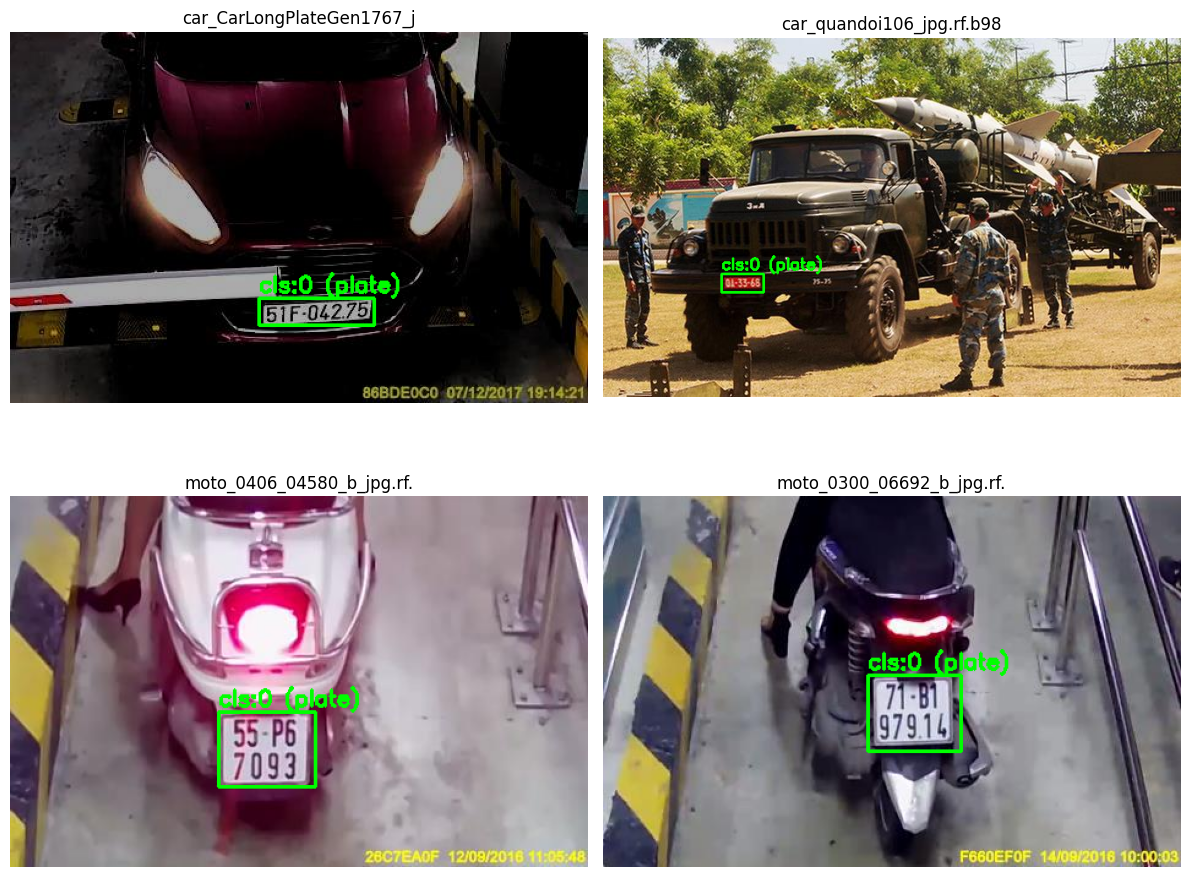

In [15]:
import matplotlib.pyplot as plt
import cv2


def draw_yolo_boxes(img_path, lbl_path):
    img = cv2.imread(img_path)
    h, w, _ = img.shape
    if os.path.exists(lbl_path):
        with open(lbl_path, "r") as f:
            for line in f:
                parts = line.strip().split()
                if len(parts) >= 5:
                    cls_id, xc, yc, bw, bh = int(parts[0]), float(parts[1]), float(parts[2]), float(parts[3]), float(parts[4])
                    x1 = int((xc - bw / 2) * w)
                    y1 = int((yc - bh / 2) * h)
                    x2 = int((xc + bw / 2) * w)
                    y2 = int((yc + bh / 2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)
                    cv2.putText(img, f"cls:{cls_id} (plate)", (x1, max(20, y1 - 5)), 
                                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 255, 0), 2)
    return cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
# Pick 2 cars and 2 motorcycles
car_sample = random.sample(cars, min(2, len(cars)))
moto_sample = random.sample(motos, min(2, len(motos)))
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
for ax, fname in zip(axes.flatten(), car_sample + moto_sample):
    img_p = f"{dataset_path}/train/images/{fname}"
    lbl_p = f"{dataset_path}/train/labels/{os.path.splitext(fname)[0]}.txt"
    ax.imshow(draw_yolo_boxes(img_p, lbl_p))
    ax.set_title(fname[:25])
    ax.axis("off")
plt.tight_layout()
plt.show()

In [16]:
img_dir = "/content/dataset_unified/train/images"
lbl_dir = "/content/dataset_unified/train/labels"

all_imgs = [f for f in os.listdir(img_dir) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]
all_lbls = os.listdir(lbl_dir)

# Count which label files are 0 bytes (negatives) vs > 0 bytes (plates)
empty_labels = [f for f in all_lbls if os.path.getsize(os.path.join(lbl_dir, f)) == 0]
plate_labels = [f for f in all_lbls if os.path.getsize(os.path.join(lbl_dir, f)) > 0]

print(f"Total Training Images : {len(all_imgs)}")
print(f"Total Training Labels : {len(all_lbls)}")
print(f"  -> License Plates   : {len(plate_labels)} images (1400 cars + 1397 bikes)")
print(f"  -> Pure Negatives   : {len(empty_labels)} images (0-byte empty files)")

Total Training Images : 3197
Total Training Labels : 3197
  -> License Plates   : 3077 images (1400 cars + 1397 bikes)
  -> Pure Negatives   : 120 images (0-byte empty files)


Applied Fine Tuning (leveraging a pretrained model to specialise it in finding license plates)

I did not use any optimisation paths like: adding shears or freezing any base layers.


testing dataset integrity

In [17]:
# Check 3: 1-epoch dry run to test Ultralytics pipeline integrity
!yolo detect train data=/content/dataset_unified/data.yaml model=yolo11s.pt epochs=1 imgsz=640 batch=16

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_unified/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=1, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, opt

## yolo11n but 40 epochs

also, on the side note: mp950-95 shows how tight the bounding boxes are fit around the license plate. since we're doing OCR within a bounding box, i'd need to manually expand the bounding boxes before pushing it to an OCR model that will extract the text.

initial testing; to re-train same best model but now with skewed data set to analyse performance

In [ ]:
# Train YOLO11n on the skew-augmented balanced fleet
model = YOLO("yolo11n.pt")
results = model.train(
    data=f"{unified_dir}/data.yaml",
    epochs=40,
    imgsz=640,
    batch=16,
    patience=0,
    exist_ok=True,
    name="balanced_skew_robust_yolo11n"
)
# Export production ONNX weight
best_pt = YOLO("runs/detect/balanced_skew_robust_yolo11n/weights/best.pt")
best_pt.export(format="onnx", imgsz=640, simplify=True, dynamic = True) # dynamic is important.

Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/dataset_unified/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=40, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=balanced_skew_robust_yolo11n, nbs=64, nms=None, opset=No

'runs/detect/balanced_skew_robust_yolo11n/weights/best.onnx'

216pm ended here

# Download Trained best.pt Weights to Your Local Machine

Model is downloaded to colab notebook's local runtime; please re-download best.pt from there and replace it in your directory's Models_yolo, if retrained.


If on VSCODE's colab extension .ipynb (what I used), go to the colab extension, click on the existing remote server, and find /runs/... to download the .pt model.